# INF264 – Project 1: Decision Trees

This notebook loads the churn dataset, performs model selection for our own decision tree implementation and for scikit-learn's `DecisionTreeClassifier`, compares the two on a held-out test set, and computes permutation feature importance for the best model.

The decision tree itself (ID3, entropy/Gini, `max_depth`) and `permutation_importance` are implemented in `decision_tree.py`; this notebook only loads the data, runs the experiments, and reports the results, as required by the project description.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from sklearn.tree import DecisionTreeClassifier

from decision_tree import DecisionTree, permutation_importance

## 1. Load and inspect the data

We load `churn-data.csv` with `numpy.genfromtxt`, which gives a structured array that we convert into a plain `X` (features) / `y` (label) pair. All 19 feature columns are already numeric (categorical features were pre-encoded), so no further preprocessing is needed before fitting the trees.

In [2]:
data = np.genfromtxt("churn-data.csv", delimiter=",", dtype=float, names=True)
feature_names = list(data.dtype.names[:-1])
target_name = data.dtype.names[-1]
X = np.array([data[feature] for feature in feature_names]).T
y = data[target_name].astype(int)
print(f"Feature column names: {feature_names}")
print(f"Target column name: {target_name}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Feature column names: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Target column name: Churn
X shape: (7032, 19)
y shape: (7032,)


## 2. Train / validation / test split

We first split off a **test set** (20%) that is not touched again until the very end. Model selection (hyperparameter tuning) uses only `X_train/y_train`, so the test accuracy we report at the end is an unbiased estimate of generalisation performance. The split is stratified on `y` to preserve the class balance (churn vs. no churn) in both parts.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## 3. Model selection

We tune two hyperparameters with 5-fold **stratified cross-validation** on `X_train`/`y_train`, using accuracy as the selection metric:

- `max_depth`: `[3, 5, 7, 10, None]`
- `criterion`: `["entropy", "gini"]`

Stratification matters here because the churn classes are imbalanced. `run_cv_grid` below runs this procedure for either our own `DecisionTree` or sklearn's `DecisionTreeClassifier`, so both implementations are tuned with the exact same folds — this keeps the later comparison fair and avoids duplicating the CV loop for each implementation.

In [4]:
def run_cv_grid(
        model_type: type[DecisionTree] | type[DecisionTreeClassifier], 
        depths: list[int | None], 
        criteria: list[str],
        scorer: callable
    ) -> tuple:
    """
    model_type: The decision tree implementation to evaluate. Can be the custom DecisionTree or sklearn's DecisionTreeClassifier.
    depths: The maximum depths to test for the decision tree. None means that the tree can grow until another stopping condition is reached.
    criteria: The impurity measures to test. Can contain "entropy" and/or "gini".
    scorer: A function that takes the true labels and predicted labels as input and returns a performance score
        (e.g. sklearn.metrics.accuracy_score or sklearn.metrics.balanced_accuracy_score). Higher is assumed to be better.

    Returns:
    cv_scores: A dictionary containing the mean cross-validation accuracy for each (criterion, depth) combination.
    best_criterion: The criterion that achieved the highest mean cross-validation accuracy.
    best_depth: The maximum depth that achieved the highest mean cross-validation accuracy.
    """

    # Store the mean validation accuracy for each combination of criterion and maximum tree depth.
    cv_scores = {}

    # Test every combination of criterion and maximum depth.
    for criterion in criteria:
        for depth in depths:

            # Use 5-fold stratified cross-validation.
            # Stratification ensures that each fold has a similar class distribution to the original training data.
            skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
            fold_scores = []

            # Split the training data into training and validation folds.
            for train_idx, val_idx in skf.split(X_train, y_train):

                # Create the selected decision tree implementation with the current hyperparameter combination.
                if model_type == DecisionTree:
                    model = DecisionTree(max_depth=depth, criterion=criterion)
                elif model_type == DecisionTreeClassifier:
                    model = DecisionTreeClassifier(max_depth=depth, criterion=criterion, random_state=42)

                # Train the model using only the training part of the fold.
                model.fit(X_train[train_idx], y_train[train_idx])

                # Predict the classes of the samples in the validation fold.
                preds = model.predict(X_train[val_idx])

                # Calculate and store the validation accuracy.
                fold_scores.append(scorer(y_train[val_idx], preds))

            # Calculate the mean accuracy across all five folds.
            # This gives a more reliable estimate of model performance than using a single train/validation split.
            cv_scores[(criterion, depth)] = np.mean(fold_scores)

    # Print the mean cross-validation accuracy for every criterion and maximum depth combination.
    df = pd.DataFrame(
        [(c, d, s) for (c, d), s in cv_scores.items()],
        columns=["Criterion", "Max depth", "CV-score"]
    )
    df.sort_values("CV-score", ascending=False)

    display(df)

    # Select and print the hyperparameter combination with the highest mean cross-validation accuracy.
    best_criterion, best_depth = max(cv_scores, key=cv_scores.get)
    print("\nBest combination:", best_criterion, best_depth, "CV accuracy:", cv_scores[(best_criterion, best_depth)]) 

    return cv_scores, best_criterion, best_depth

### Own implementation — grid search

In [5]:
max_depths = [3, 5, 7, 10, None]
criteria = ["entropy", "gini"]

cv_scores, best_criterion, best_depth = run_cv_grid(DecisionTree, max_depths, criteria, accuracy_score)

,Criterion,Max depth,CV-score
0,entropy,3.0,0.783289
1,entropy,5.0,0.792889
2,entropy,7.0,0.791467
3,entropy,10.0,0.759111
4,entropy,NaN,0.733689
5,gini,3.0,0.783289
6,gini,5.0,0.794311
7,gini,7.0,0.788800
8,gini,10.0,0.757156
9,gini,NaN,0.727289



Best combination: gini 5 CV accuracy: 0.7943111111111111


### Train the final model and evaluate on the test set

We refit the chosen `(criterion, max_depth)` on the full `X_trainval`/`y_train` and evaluate once on the held-out test set.

In [6]:
best_model = DecisionTree(max_depth=best_depth, criterion=best_criterion)
best_model.fit(X_train, y_train)
test_preds = best_model.predict(X_test)
print("Test accuracy (own implementation):", accuracy_score(y_test, test_preds))

Test accuracy (own implementation): 0.7825159914712153


## 4. Model selection — scikit-learn baseline

For a fair comparison we reuse `run_cv_grid` with the exact same `max_depth`/`criterion` grid (and, since `StratifiedKFold` is re-seeded identically inside the function, the exact same folds) on `sklearn.tree.DecisionTreeClassifier`.

In [7]:
sklearn_cv_scores, sklearn_best_criterion, sklearn_best_depth = run_cv_grid(DecisionTreeClassifier, max_depths, criteria, accuracy_score)

,Criterion,Max depth,CV-score
0,entropy,3.0,0.783467
1,entropy,5.0,0.789867
2,entropy,7.0,0.784889
3,entropy,10.0,0.766756
4,entropy,NaN,0.734756
5,gini,3.0,0.783467
6,gini,5.0,0.792178
7,gini,7.0,0.783822
8,gini,10.0,0.765333
9,gini,NaN,0.740089



Best combination: gini 5 CV accuracy: 0.7921777777777776


### Train the final sklearn model and evaluate on the test set

In [8]:
best_sklearn_model = DecisionTreeClassifier(max_depth=sklearn_best_depth, criterion=sklearn_best_criterion, random_state=42)
best_sklearn_model.fit(X_train, y_train)
sklearn_test_preds = best_sklearn_model.predict(X_test)
print("Test accuracy (sklearn):", accuracy_score(y_test, sklearn_test_preds))

Test accuracy (sklearn): 0.7818052594171997


## 5. Comparing the two implementations

We report cross-validation accuracy (used for model selection), test accuracy, and test F1-score for both implementations side by side. Both ended up selecting the same combination (`criterion="gini"`, `max_depth=5`), and the two implementations perform very similarly on the held-out test set.

In [9]:
print(f"{'Model':<15}{'CV accuracy':<15}{'Test accuracy':<15}{'Test F1':<15}")
print(f"{'Own':<15}{cv_scores[(best_criterion, best_depth)]:<15.4f}{accuracy_score(y_test, test_preds):<15.4f}{f1_score(y_test, test_preds):<15.4f}")
print(f"{'Sklearn':<15}{sklearn_cv_scores[(sklearn_best_criterion, sklearn_best_depth)]:<15.4f}{accuracy_score(y_test, sklearn_test_preds):<15.4f}{f1_score(y_test, sklearn_test_preds):<15.4f}")

Model          CV accuracy    Test accuracy  Test F1        
Own            0.7943         0.7825         0.5248         
Sklearn        0.7922         0.7818         0.5492         


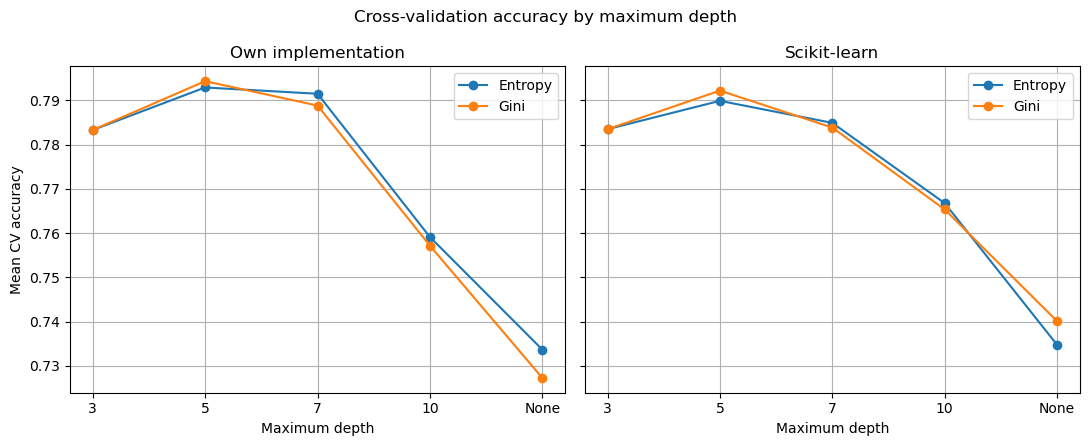

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
depth_labels = ["3", "5", "7", "10", "None"]

own_entropy = [cv_scores[("entropy", d)] for d in max_depths]
own_gini = [cv_scores[("gini", d)] for d in max_depths]
sk_entropy = [sklearn_cv_scores[("entropy", d)] for d in max_depths]
sk_gini = [sklearn_cv_scores[("gini", d)] for d in max_depths]

axes[0].plot(depth_labels, own_entropy, marker="o", label="Entropy")
axes[0].plot(depth_labels, own_gini, marker="o", label="Gini")
axes[0].set_title("Own implementation")
axes[0].set_xlabel("Maximum depth")
axes[0].set_ylabel("Mean CV accuracy")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(depth_labels, sk_entropy, marker="o", label="Entropy")
axes[1].plot(depth_labels, sk_gini, marker="o", label="Gini")
axes[1].set_title("Scikit-learn")
axes[1].set_xlabel("Maximum depth")
axes[1].grid(True)
axes[1].legend()

fig.suptitle("Cross-validation accuracy by maximum depth")
fig.tight_layout()
fig.savefig("cv_accuracy_comparison.png")
plt.show()

## 6. Feature importance — permutation importance

Using the best model from our own implementation, we compute permutation importance on the test set following the [scikit-learn outline](https://scikit-learn.org/stable/modules/permutation_importance.html#outline-of-the-permutation-importance-algorithm), with `n_repeats=30` and a fixed seed. The plot below (also saved as `permutation_importance.png`) shows the mean decrease in accuracy per feature, with error bars for the standard deviation across repeats.

gender: 0.0000
SeniorCitizen: 0.0020
Partner: 0.0000
Dependents: 0.0005
tenure: 0.0277
PhoneService: 0.0000
MultipleLines: 0.0000
InternetService: 0.0000
OnlineSecurity: 0.0334
OnlineBackup: -0.0011
DeviceProtection: 0.0000
TechSupport: 0.0000
StreamingTV: -0.0016
StreamingMovies: 0.0000
Contract: 0.0247
PaperlessBilling: 0.0000
PaymentMethod: 0.0000
MonthlyCharges: 0.0270
TotalCharges: 0.0269


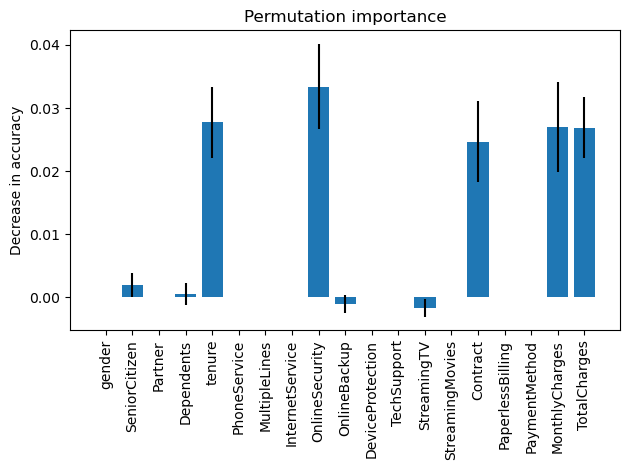

In [11]:
result = permutation_importance(best_model, X_test, y_test, accuracy_score, n_repeats=30, seed=42)

for name, importance in zip(feature_names, result["importances_mean"]):
    print(f"{name}: {importance:.4f}")

plt.bar(feature_names, result["importances_mean"], yerr=result["importances_std"])
plt.xticks(rotation=90)
plt.ylabel("Decrease in accuracy")
plt.title("Permutation importance")
plt.tight_layout()
plt.savefig("permutation_importance.png")
plt.show()

## Notes

- All random seeds are fixed (`random_state=42` / `seed=42`), so the numbers above are reproducible.
- See the accompanying report for a discussion of the model selection choices, the results, and the limitations of permutation importance.